In [1]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from xgboost import XGBClassifier

df = pd.read_csv("AmesHousing.csv", sep="\t", keep_default_na=False,  # pandas turns the strings "NA"/"None" into NaN; here they mean the feature is absent (no pool, no alley), not missing data
    na_values=[""])


def clean_task1(data):
    """Zeilenweise Behandlung fehlender Werte aus Aufgabe 1 (keine Statistik ueber andere Zeilen)."""
    data = data.copy()
    absence_cols = ["Pool QC", "Misc Feature", "Alley", "Fence", "Mas Vnr Type", "Fireplace Qu",
                    "Garage Type", "Garage Finish", "Garage Qual", "Garage Cond",
                    "Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
    data[absence_cols] = data[absence_cols].replace("NA", "None").fillna("None")

    # Muss vor der Imputation von Lot Frontage (in der Pipeline) entstehen.
    data["Lot Frontage Missing"] = data["Lot Frontage"].isnull().astype(int)

    # Leer nur dann, wenn Garage/Keller/Verblendung fehlt -> Groesse 0.
    zero_cols = ["Garage Area", "Garage Cars", "BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF",
                 "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath", "Mas Vnr Area"]
    data[zero_cols] = data[zero_cols].fillna(0)
    data["Garage Yr Blt"] = data["Garage Yr Blt"].fillna(0)

    # MS SubClass ist ein Gebaeudetyp-Code, keine Groesse.
    data["MS SubClass"] = data["MS SubClass"].astype(str)
    return data


df_clean = clean_task1(df)

print(f"Bereinigter Datensatz: {df_clean.shape[0]} Zeilen, {df_clean.shape[1]} Spalten")
print("Noch fehlende Werte (werden in der Pipeline imputiert):")
display(df_clean.isnull().sum()[lambda counts: counts > 0])
display(df_clean.head())

Bereinigter Datensatz: 2930 Zeilen, 83 Spalten
Noch fehlende Werte (werden in der Pipeline imputiert):


Lot Frontage    490
Electrical        1
dtype: int64

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice,Lot Frontage Missing
0,1,526301100,20,RL,141.0,31770,Pave,None,IR1,Lvl,...,None,None,None,0,5,2010,WD,Normal,215000,0
1,2,526350040,20,RH,80.0,11622,Pave,None,Reg,Lvl,...,None,MnPrv,None,0,6,2010,WD,Normal,105000,0
2,3,526351010,20,RL,81.0,14267,Pave,None,IR1,Lvl,...,None,None,Gar2,12500,6,2010,WD,Normal,172000,0
3,4,526353030,20,RL,93.0,11160,Pave,None,Reg,Lvl,...,None,None,None,0,4,2010,WD,Normal,244000,0
4,5,527105010,60,RL,74.0,13830,Pave,None,IR1,Lvl,...,None,MnPrv,None,0,3,2010,WD,Normal,189900,0


In [2]:
class_names = [
    "< 100.000",
    "100.000 - < 130.000",
    "130.000 - < 180.000",
    "180.000 - < 250.000",
    "250.000 - < 400.000",
    ">= 400.000",
]
price_bins = [-np.inf, 100_000, 130_000, 180_000, 250_000, 400_000, np.inf]

y = pd.cut(
    df_clean["SalePrice"],
    bins=price_bins,
    labels=False,
    right=False,
).astype("int64")
X = df_clean.drop(columns=["SalePrice", "Order", "PID"])

class_distribution = y.value_counts().sort_index()
display(
    class_distribution.rename(index=dict(enumerate(class_names)))
    .rename("Anzahl")
    .to_frame()
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
print(f"Trainingsdaten: {X_train.shape[0]} | Testdaten: {X_test.shape[0]}")

,Anzahl
SalePrice,
< 100.000,237
100.000 - < 130.000,509
130.000 - < 180.000,1037
180.000 - < 250.000,686
250.000 - < 400.000,397
>= 400.000,64


Trainingsdaten: 2344 | Testdaten: 586


In [3]:
display(
    pd.DataFrame({
        "SalePrice": df_clean["SalePrice"],
        "class_id": y,
        "price_class": y.map(dict(enumerate(class_names))),
    }).head(10)
)

,SalePrice,class_id,price_class
0,215000,3,180.000 - < 250.000
1,105000,1,100.000 - < 130.000
2,172000,2,130.000 - < 180.000
3,244000,3,180.000 - < 250.000
4,189900,3,180.000 - < 250.000
5,195500,3,180.000 - < 250.000
6,213500,3,180.000 - < 250.000
7,191500,3,180.000 - < 250.000
8,236500,3,180.000 - < 250.000
9,189000,3,180.000 - < 250.000


In [4]:
class NeighborhoodMedianImputer(BaseEstimator, TransformerMixin):
    """Fuellt Lot Frontage mit dem Median der Nachbarschaft (gelernt auf den Trainingsdaten)."""

    def fit(self, X, y=None):
        self.neighborhood_medians_ = X.groupby("Neighborhood")["Lot Frontage"].median()
        self.global_median_ = X["Lot Frontage"].median()
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        X["Lot Frontage"] = (
            X["Lot Frontage"]
            .fillna(X["Neighborhood"].map(self.neighborhood_medians_))
            .fillna(self.global_median_)
        )
        return X

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_


# Reihenfolge jeweils von schlecht nach gut; "None" = nicht vorhanden.
quality_scale = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
ordinal_categories = {
    "Exter Qual": quality_scale,
    "Exter Cond": quality_scale,
    "Bsmt Qual": quality_scale,
    "Bsmt Cond": quality_scale,
    "Heating QC": quality_scale,
    "Kitchen Qual": quality_scale,
    "Garage Qual": quality_scale,
    "Garage Cond": quality_scale,
    "Fireplace Qu": quality_scale,
    "Pool QC": quality_scale,
    "Bsmt Exposure": ["None", "No", "Mn", "Av", "Gd"],
    "BsmtFin Type 1": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "BsmtFin Type 2": ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"],
    "Garage Finish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "Paved Drive": ["N", "P", "Y"],
    "Land Slope": ["Sev", "Mod", "Gtl"],
    "Lot Shape": ["IR3", "IR2", "IR1", "Reg"],
    "Utilities": ["ELO", "NoSeWa", "NoSewr", "AllPub"],
    "Central Air": ["N", "Y"],
}
ordinal_features = list(ordinal_categories)
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    column
    for column in X_train.select_dtypes(include=["object", "category", "str"]).columns
    if column not in ordinal_categories
]

numeric_preprocessor = Pipeline(
    steps=[("imputer", SimpleImputer(strategy="median"))]
)
ordinal_preprocessor = OrdinalEncoder(
    categories=[ordinal_categories[column] for column in ordinal_features],
    handle_unknown="use_encoded_value",
    unknown_value=-1,
)
categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = Pipeline(
    steps=[
        ("lot_frontage", NeighborhoodMedianImputer()),
        (
            "encode",
            ColumnTransformer(
                transformers=[
                    ("numeric", numeric_preprocessor, numeric_features),
                    ("ordinal", ordinal_preprocessor, ordinal_features),
                    ("categorical", categorical_preprocessor, categorical_features),
                ]
            ),
        ),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            XGBClassifier(
                objective="multi:softprob",
                num_class=len(class_names),
                eval_metric="mlogloss",
                n_estimators=350,
                learning_rate=0.05,
                max_depth=5,
                subsample=0.85,
                colsample_bytree=0.85,
                reg_lambda=1.0,
                tree_method="hist",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

In [5]:
from scipy import sparse

fitted_preprocessor = model.named_steps["preprocessor"]
encoded_matrix = fitted_preprocessor.transform(X)
encoded_feature_names = fitted_preprocessor.get_feature_names_out()

if sparse.issparse(encoded_matrix):
    X_encoded = pd.DataFrame.sparse.from_spmatrix(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )
else:
    X_encoded = pd.DataFrame(
        encoded_matrix,
        index=X.index,
        columns=encoded_feature_names,
    )

print(f"Kodierter Datensatz: {X_encoded.shape[0]} Zeilen, {X_encoded.shape[1]} Merkmale")
display(X_encoded.head())

Kodierter Datensatz: 2930 Zeilen, 246 Merkmale


,numeric__Lot Frontage,numeric__Lot Area,numeric__Overall Qual,numeric__Overall Cond,numeric__Year Built,numeric__Year Remod/Add,numeric__Mas Vnr Area,numeric__BsmtFin SF 1,numeric__BsmtFin SF 2,numeric__Bsmt Unf SF,...,categorical__Sale Type_New,categorical__Sale Type_Oth,categorical__Sale Type_VWD,categorical__Sale Type_WD,categorical__Sale Condition_Abnorml,categorical__Sale Condition_AdjLand,categorical__Sale Condition_Alloca,categorical__Sale Condition_Family,categorical__Sale Condition_Normal,categorical__Sale Condition_Partial
0,141.0,31770.0,6.0,5.0,1960.0,1960.0,112.0,639.0,0.0,441.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,80.0,11622.0,5.0,6.0,1961.0,1961.0,0.0,468.0,144.0,270.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,81.0,14267.0,6.0,6.0,1958.0,1958.0,108.0,923.0,0.0,406.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,93.0,11160.0,7.0,5.0,1968.0,1968.0,0.0,1065.0,0.0,1045.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,74.0,13830.0,5.0,5.0,1997.0,1998.0,0.0,791.0,0.0,137.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [6]:
baseline_accuracy = y_test.value_counts(normalize=True).max()
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Balanced Accuracy: {balanced_accuracy_score(y_test, y_pred):.3f}")
print(f"Mehrheits-Baseline: {baseline_accuracy:.3f}\n")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0,
    )
)

Accuracy:          0.771
Balanced Accuracy: 0.723
Mehrheits-Baseline: 0.353

                     precision    recall  f1-score   support

          < 100.000       0.76      0.71      0.73        48
100.000 - < 130.000       0.69      0.67      0.68       102
130.000 - < 180.000       0.77      0.85      0.80       207
180.000 - < 250.000       0.83      0.74      0.78       137
250.000 - < 400.000       0.80      0.84      0.82        79
         >= 400.000       0.78      0.54      0.64        13

           accuracy                           0.77       586
          macro avg       0.77      0.72      0.74       586
       weighted avg       0.77      0.77      0.77       586



In [7]:
holdout_results = []
overall_class_shares = y.value_counts(normalize=True).reindex(
    range(len(class_names)), fill_value=0
)


def holdout_row(name, fitted_model, X_tr, y_tr, X_te, y_te):
    y_hat = fitted_model.predict(X_te)
    return {
        "Verfahren": name,
        "Train Accuracy": accuracy_score(y_tr, fitted_model.predict(X_tr)),
        "Train F1 (macro)": f1_score(
            y_tr, fitted_model.predict(X_tr), average="macro", zero_division=0
        ),
        "Test Accuracy": accuracy_score(y_te, y_hat),
        "Test Balanced Accuracy": balanced_accuracy_score(y_te, y_hat),
        "Test Precision (macro)": precision_score(
            y_te, y_hat, average="macro", zero_division=0
        ),
        "Test Recall (macro)": recall_score(
            y_te, y_hat, average="macro", zero_division=0
        ),
        "Test F1 (macro)": f1_score(y_te, y_hat, average="macro", zero_division=0),
        "Max. Klassenanteil-Abweichung": (
            y_te.value_counts(normalize=True)
            .reindex(range(len(class_names)), fill_value=0)
            .sub(overall_class_shares)
            .abs()
            .max()
        ),
    }


# Das bereits trainierte Modell entspricht dem 20%-Split mit Stratifikation.
holdout_results.append(
    holdout_row("Hold-out 20% (stratifiziert)", model, X_train, y_train, X_test, y_test)
)

for test_size in (0.1, 0.2):
    for stratified in (True, False):
        if test_size == 0.2 and stratified:
            continue

        X_train_exp, X_test_exp, y_train_exp, y_test_exp = train_test_split(
            X,
            y,
            test_size=test_size,
            random_state=42,
            stratify=y if stratified else None,
        )
        experiment_model = clone(model)
        experiment_model.fit(X_train_exp, y_train_exp)
        split_name = "stratifiziert" if stratified else "nicht stratifiziert"
        holdout_results.append(
            holdout_row(
                f"Hold-out {test_size:.0%} ({split_name})",
                experiment_model,
                X_train_exp,
                y_train_exp,
                X_test_exp,
                y_test_exp,
            )
        )

holdout_results = pd.DataFrame(holdout_results)
holdout_results["Train-Test Abstand (Accuracy)"] = (
    holdout_results["Train Accuracy"] - holdout_results["Test Accuracy"]
)
holdout_results["Train-Test Abstand (F1 macro)"] = (
    holdout_results["Train F1 (macro)"] - holdout_results["Test F1 (macro)"]
)
display(holdout_results.set_index("Verfahren").round(3).T)

Verfahren,Hold-out 20% (stratifiziert),Hold-out 10% (stratifiziert),Hold-out 10% (nicht stratifiziert),Hold-out 20% (nicht stratifiziert)
Train Accuracy,1.000,0.998,0.997,0.999
Train F1 (macro),1.000,0.999,0.998,0.999
Test Accuracy,0.771,0.765,0.771,0.778
Test Balanced Accuracy,0.723,0.733,0.711,0.716
Test Precision (macro),0.770,0.815,0.744,0.760
Test Recall (macro),0.723,0.733,0.711,0.716
Test F1 (macro),0.742,0.764,0.721,0.734
Max. Klassenanteil-Abweichung,0.001,0.002,0.064,0.028
Train-Test Abstand (Accuracy),0.228,0.233,0.225,0.221
Train-Test Abstand (F1 macro),0.258,0.235,0.277,0.266


In [8]:
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_macro": make_scorer(precision_score, average="macro", zero_division=0),
    "recall_macro": make_scorer(recall_score, average="macro", zero_division=0),
    "f1_macro": make_scorer(f1_score, average="macro", zero_division=0),
}
metric_labels = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision_macro": "Precision (macro)",
    "recall_macro": "Recall (macro)",
    "f1_macro": "F1 (macro)",
}
cv_summary = []
cv_fold_results = []

for n_splits in (5, 10):
    for stratified in (True, False):
        if stratified:
            cv = StratifiedKFold(
                n_splits=n_splits, shuffle=True, random_state=42
            )
            cv_name = "StratifiedKFold"
        else:
            cv = KFold(n_splits=n_splits, shuffle=True, random_state=42)
            cv_name = "KFold"

        scores = cross_validate(
            clone(model),
            X,
            y,
            cv=cv,
            scoring=scoring,
            return_train_score=True,
            n_jobs=1,
            error_score="raise",
        )
        experiment_name = f"{cv_name}, k={n_splits}"
        fold_scores = pd.DataFrame(
            {
                "Verfahren": experiment_name,
                "Fold": np.arange(1, n_splits + 1),
                "Train Accuracy": scores["train_accuracy"],
                "Train F1 (macro)": scores["train_f1_macro"],
                **{
                    f"Validation {label}": scores[f"test_{metric}"]
                    for metric, label in metric_labels.items()
                },
            }
        )
        cv_fold_results.append(fold_scores)

        summary_row = {"Verfahren": experiment_name}
        for metric, label in metric_labels.items():
            summary_row[f"{label} (Mittel)"] = scores[f"test_{metric}"].mean()
            summary_row[f"{label} (Std)"] = scores[f"test_{metric}"].std(ddof=1)
        summary_row["Train-Validation Abstand (Accuracy)"] = (
            scores["train_accuracy"].mean() - scores["test_accuracy"].mean()
        )
        summary_row["Train-Validation Abstand (F1 macro)"] = (
            scores["train_f1_macro"].mean() - scores["test_f1_macro"].mean()
        )
        cv_summary.append(summary_row)

cv_summary = pd.DataFrame(cv_summary)
cv_fold_results = pd.concat(cv_fold_results, ignore_index=True)
display(cv_summary.set_index("Verfahren").round(3).T)
display(cv_fold_results.round(3))

Verfahren,"StratifiedKFold, k=5","KFold, k=5","StratifiedKFold, k=10","KFold, k=10"
Accuracy (Mittel),0.766,0.763,0.766,0.773
Accuracy (Std),0.017,0.026,0.025,0.024
Balanced Accuracy (Mittel),0.720,0.730,0.724,0.735
Balanced Accuracy (Std),0.013,0.035,0.047,0.039
Precision (macro) (Mittel),0.767,0.785,0.779,0.787
Precision (macro) (Std),0.018,0.028,0.046,0.036
Recall (macro) (Mittel),0.720,0.730,0.724,0.735
Recall (macro) (Std),0.013,0.035,0.047,0.039
F1 (macro) (Mittel),0.739,0.750,0.743,0.753
F1 (macro) (Std),0.012,0.027,0.046,0.034


,Verfahren,Fold,Train Accuracy,Train F1 (macro),Validation Accuracy,Validation Balanced Accuracy,Validation Precision (macro),Validation Recall (macro),Validation F1 (macro)
0,"StratifiedKFold, k=5",1,0.999,0.999,0.785,0.728,0.787,0.728,0.751
1,"StratifiedKFold, k=5",2,0.999,0.999,0.768,0.713,0.768,0.713,0.735
2,"StratifiedKFold, k=5",3,0.999,0.999,0.751,0.738,0.766,0.738,0.751
3,"StratifiedKFold, k=5",4,1.000,1.000,0.778,0.716,0.773,0.716,0.739
4,"StratifiedKFold, k=5",5,1.000,1.000,0.746,0.707,0.739,0.707,0.721
5,"KFold, k=5",1,0.999,0.999,0.788,0.739,0.774,0.739,0.754
6,"KFold, k=5",2,0.998,0.999,0.744,0.672,0.806,0.672,0.716
7,"KFold, k=5",3,0.999,0.999,0.747,0.754,0.778,0.754,0.765
8,"KFold, k=5",4,0.999,0.999,0.742,0.723,0.748,0.723,0.732
9,"KFold, k=5",5,0.999,0.999,0.795,0.760,0.819,0.760,0.784


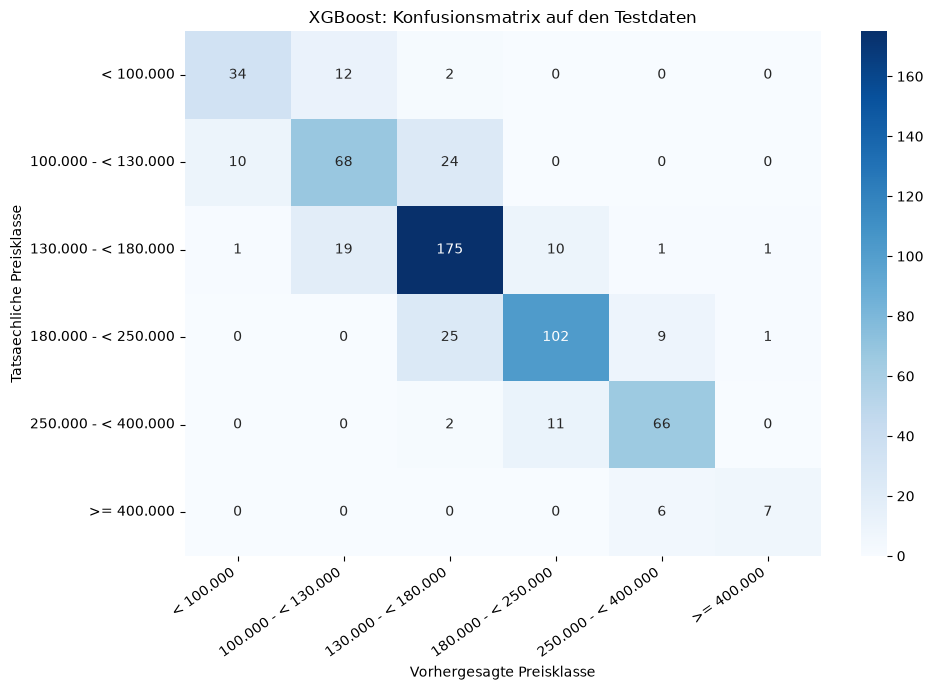

In [9]:
matrix = confusion_matrix(y_test, y_pred, labels=list(range(len(class_names))))
plt.figure(figsize=(10, 7))
sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.xlabel("Vorhergesagte Preisklasse")
plt.ylabel("Tatsaechliche Preisklasse")
plt.title("XGBoost: Konfusionsmatrix auf den Testdaten")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Model diagnostics


### Shared setup
Run once before the sections below. The cells use the model and test split created earlier.


In [10]:
from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import json
import textwrap

class_ids = np.arange(len(class_names))
y_test_array = np.asarray(y_test)
y_pred_probability = model.predict_proba(X_test)
print("Diagnostics setup complete. Run the following cells in order.")

Diagnostics setup complete. Run the following cells in order.


### Classification metrics
Accuracy is overall correctness. Macro averages weight each class equally; weighted averages account for class frequency.


In [11]:
metrics_table = pd.DataFrame(
    {
        "Metric": [
            "Precision (macro)", "Recall (macro)", "F1 (macro)",
            "Precision (weighted)", "Recall (weighted)", "F1 (weighted)",
        ],
        "Score": [
            precision_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            recall_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            f1_score(y_test_array, y_pred, labels=class_ids, average="macro", zero_division=0),
            precision_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
            recall_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
            f1_score(y_test_array, y_pred, labels=class_ids, average="weighted", zero_division=0),
        ],
    }
)
print(f"Test accuracy: {accuracy_score(y_test_array, y_pred):.3f}")
display(metrics_table.round(3))

per_class_report = classification_report(
    y_test_array,
    y_pred,
    labels=class_ids,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
display(
    pd.DataFrame(per_class_report)
    .T.loc[class_names, ["precision", "recall", "f1-score", "support"]]
    .round(3)
)


Test accuracy: 0.771


,Metric,Score
0,Precision (macro),0.770
1,Recall (macro),0.723
2,F1 (macro),0.742
3,Precision (weighted),0.772
4,Recall (weighted),0.771
5,F1 (weighted),0.770


,precision,recall,f1-score,support
< 100.000,0.756,0.708,0.731,48.0
100.000 - < 130.000,0.687,0.667,0.677,102.0
130.000 - < 180.000,0.768,0.845,0.805,207.0
180.000 - < 250.000,0.829,0.745,0.785,137.0
250.000 - < 400.000,0.805,0.835,0.820,79.0
>= 400.000,0.778,0.538,0.636,13.0


### Confusion matrix
Rows are the actual classes; columns are the predicted classes.


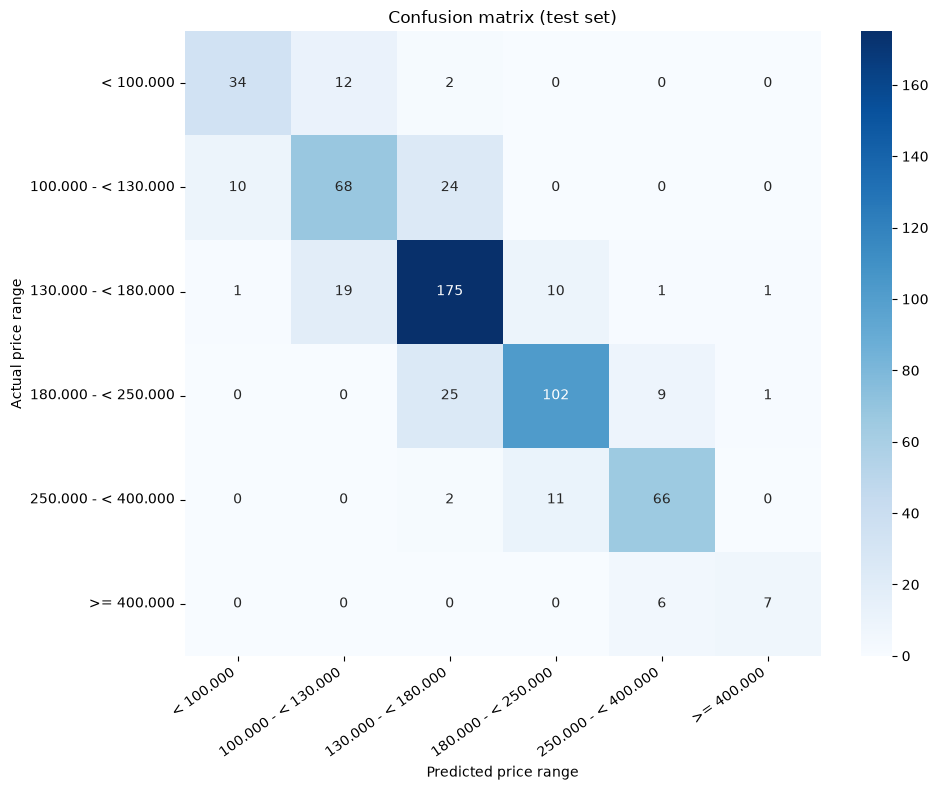

In [12]:
cm = confusion_matrix(y_test_array, y_pred, labels=class_ids)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
)
plt.xlabel("Predicted price range")
plt.ylabel("Actual price range")
plt.title("Confusion matrix (test set)")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


### ROC curves
Each panel treats one price range as positive and all other ranges as negative.


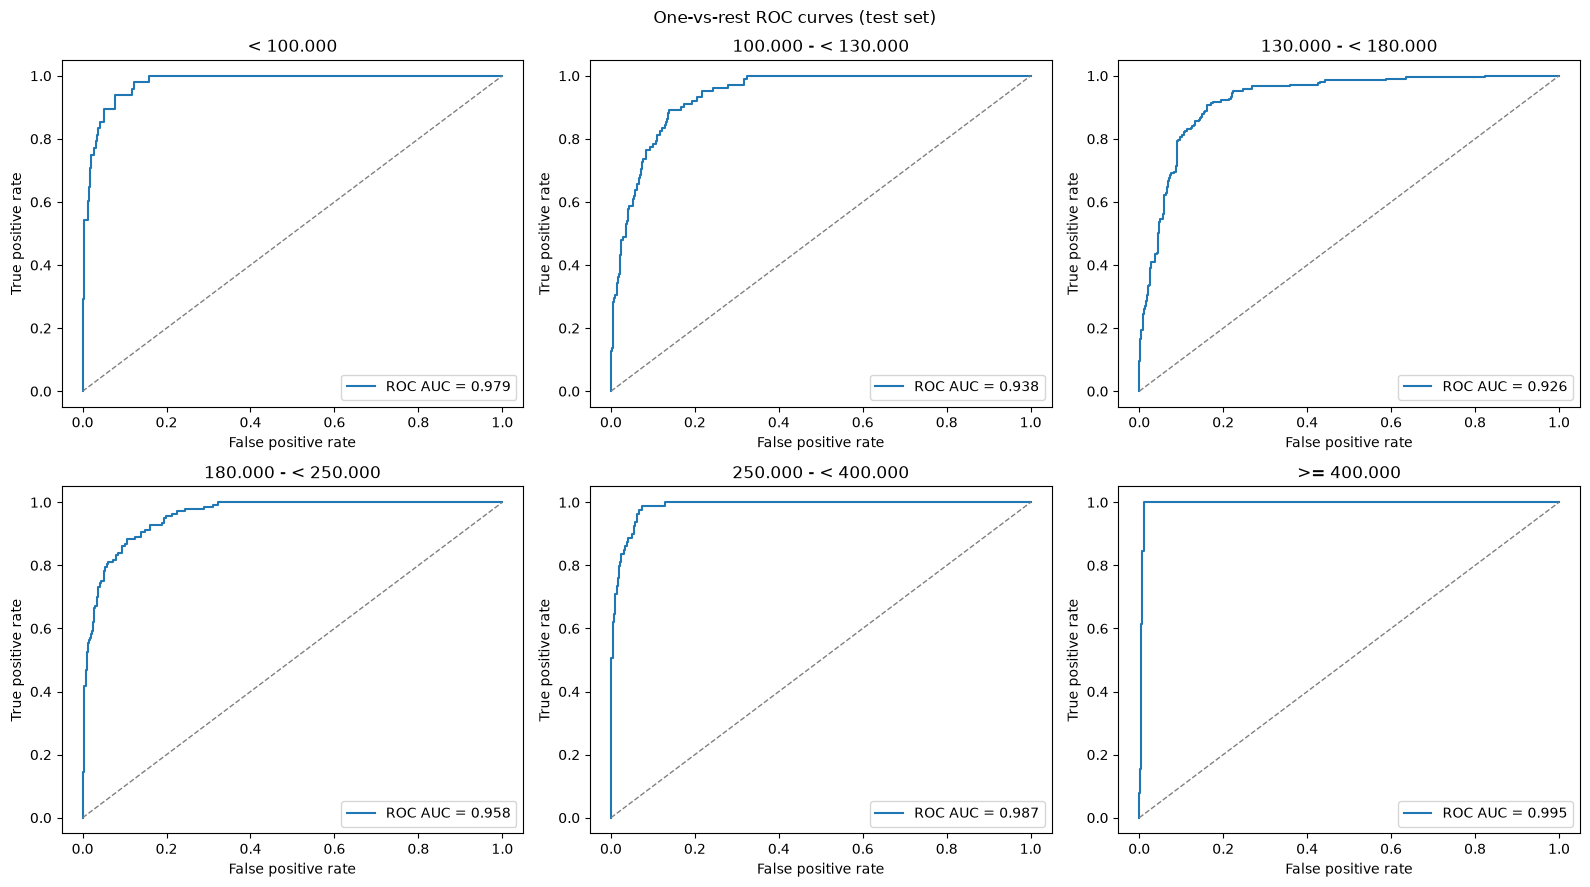

,Price range,ROC AUC
0,< 100.000,0.979
1,100.000 - < 130.000,0.938
2,130.000 - < 180.000,0.926
3,180.000 - < 250.000,0.958
4,250.000 - < 400.000,0.987
5,>= 400.000,0.995


In [13]:
# Multiclass ROC is shown one-vs-rest: one curve per price-range class.
roc_scores = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for class_id, ax in enumerate(axes.flat):
    binary_truth = (y_test_array == class_id).astype(int)
    fpr, tpr, _ = roc_curve(binary_truth, y_pred_probability[:, class_id])
    roc_auc = roc_auc_score(binary_truth, y_pred_probability[:, class_id])
    roc_scores.append({"Price range": class_names[class_id], "ROC AUC": roc_auc})
    ax.plot(fpr, tpr, label=f"ROC AUC = {roc_auc:.3f}")
    ax.plot([0, 1], [0, 1], "--", color="gray", linewidth=1)
    ax.set(title=class_names[class_id], xlabel="False positive rate", ylabel="True positive rate")
    ax.legend(loc="lower right")
fig.suptitle("One-vs-rest ROC curves (test set)")
fig.tight_layout()
plt.show()
display(pd.DataFrame(roc_scores).round(3))

### Precision-recall curves
Each panel is one-vs-rest. The dashed line shows the share of test examples in that class.


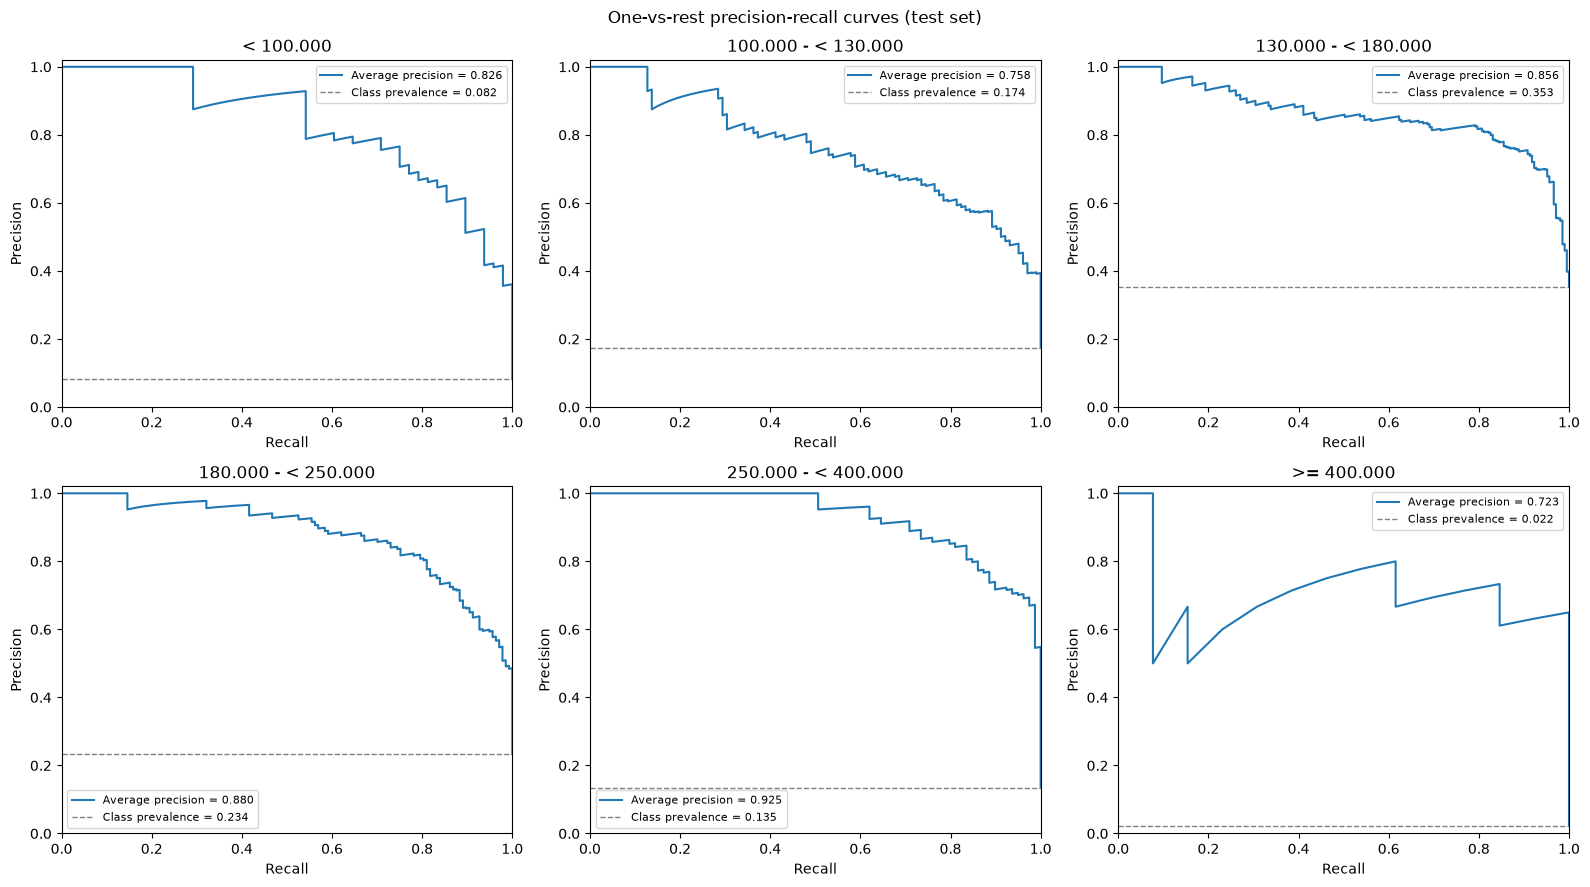

,Price range,Average precision
0,< 100.000,0.826
1,100.000 - < 130.000,0.758
2,130.000 - < 180.000,0.856
3,180.000 - < 250.000,0.880
4,250.000 - < 400.000,0.925
5,>= 400.000,0.723


In [14]:
# Precision-recall is shown one-vs-rest; the dashed line is each class's prevalence.
pr_scores = []
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for class_id, ax in enumerate(axes.flat):
    binary_truth = (y_test_array == class_id).astype(int)
    precision_curve, recall_curve, _ = precision_recall_curve(
        binary_truth, y_pred_probability[:, class_id]
    )
    average_precision = average_precision_score(binary_truth, y_pred_probability[:, class_id])
    pr_scores.append({"Price range": class_names[class_id], "Average precision": average_precision})
    ax.plot(recall_curve, precision_curve, label=f"Average precision = {average_precision:.3f}")
    ax.axhline(
        binary_truth.mean(), linestyle="--", color="gray", linewidth=1,
        label=f"Class prevalence = {binary_truth.mean():.3f}",
    )
    ax.set(
        title=class_names[class_id], xlabel="Recall", ylabel="Precision",
        xlim=(0, 1), ylim=(0, 1.02),
    )
    ax.legend(loc="best", fontsize=8)
fig.suptitle("One-vs-rest precision-recall curves (test set)")
fig.tight_layout()
plt.show()
display(pd.DataFrame(pr_scores).round(3))

### Tune probability thresholds for macro-F1
This performs cross-validation on training data to choose one cutoff per class, then evaluates once on the held-out test set.


In [15]:
# Select class-specific cutoffs using only out-of-fold training probabilities.
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probability = cross_val_predict(
    clone(model),
    X_train,
    y_train,
    cv=threshold_cv,
    method="predict_proba",
    n_jobs=1,
)
y_train_array = np.asarray(y_train)


def predict_with_thresholds(probabilities, thresholds):
    eligible = probabilities >= thresholds
    eligible_probabilities = np.where(eligible, probabilities, -np.inf)
    predictions = eligible_probabilities.argmax(axis=1)
    no_match = ~eligible.any(axis=1)
    predictions[no_match] = probabilities[no_match].argmax(axis=1)
    return predictions


def macro_f1_at_thresholds(thresholds):
    return f1_score(
        y_train_array,
        predict_with_thresholds(oof_probability, thresholds),
        labels=class_ids,
        average="macro",
        zero_division=0,
    )


threshold_candidates = [
    np.unique(
        np.r_[
            0.0,
            np.quantile(oof_probability[:, class_id], np.linspace(0, 1, 101)),
            1.0,
        ]
    )
    for class_id in class_ids
]
best_thresholds = None
best_oof_macro_f1 = -1.0
for start in (0.25, 0.5, 0.75):
    thresholds = np.full(len(class_ids), start, dtype=float)
    for _ in range(5):
        changed = False
        for class_id, candidates in enumerate(threshold_candidates):
            scores = []
            for cutoff in candidates:
                trial = thresholds.copy()
                trial[class_id] = cutoff
                scores.append(macro_f1_at_thresholds(trial))
            chosen = candidates[int(np.argmax(scores))]
            if chosen != thresholds[class_id]:
                thresholds[class_id] = chosen
                changed = True
        if not changed:
            break
    score = macro_f1_at_thresholds(thresholds)
    if score > best_oof_macro_f1:
        best_oof_macro_f1 = score
        best_thresholds = thresholds.copy()

default_oof_f1 = f1_score(
    y_train_array,
    oof_probability.argmax(axis=1),
    labels=class_ids,
    average="macro",
    zero_division=0,
)
tuned_test_predictions = predict_with_thresholds(y_pred_probability, best_thresholds)
tuned_test_f1 = f1_score(
    y_test_array,
    tuned_test_predictions,
    labels=class_ids,
    average="macro",
    zero_division=0,
)
print(f"OOF macro-F1 before tuning (argmax): {default_oof_f1:.3f}")
print(f"Best OOF macro-F1 found by threshold search: {best_oof_macro_f1:.3f}")
print(f"Test macro-F1 with default argmax: "
      f"{f1_score(y_test_array, y_pred, labels=class_ids, average='macro', zero_division=0):.3f}")
print(f"Test macro-F1 with tuned cutoffs: {tuned_test_f1:.3f}")
display(pd.DataFrame({
    "Price range": class_names,
    "Chosen probability cutoff": best_thresholds,
}).round(3))
print(
    "Decision rule: among classes that meet their cutoff, choose the one with "
    "the highest probability; if none meet a cutoff, choose the overall "
    "highest-probability class."
)


OOF macro-F1 before tuning (argmax): 0.735
Best OOF macro-F1 found by threshold search: 0.754
Test macro-F1 with default argmax: 0.742
Test macro-F1 with tuned cutoffs: 0.737


,Price range,Chosen probability cutoff
0,< 100.000,0.409
1,100.000 - < 130.000,0.267
2,130.000 - < 180.000,0.690
3,180.000 - < 250.000,0.529
4,250.000 - < 400.000,0.752
5,>= 400.000,0.227


Decision rule: among classes that meet their cutoff, choose the one with the highest probability; if none meet a cutoff, choose the overall highest-probability class.


### Feature importance: gain and split count
Gain measures average loss reduction from splits on a feature. Split count is how often the feature is used.


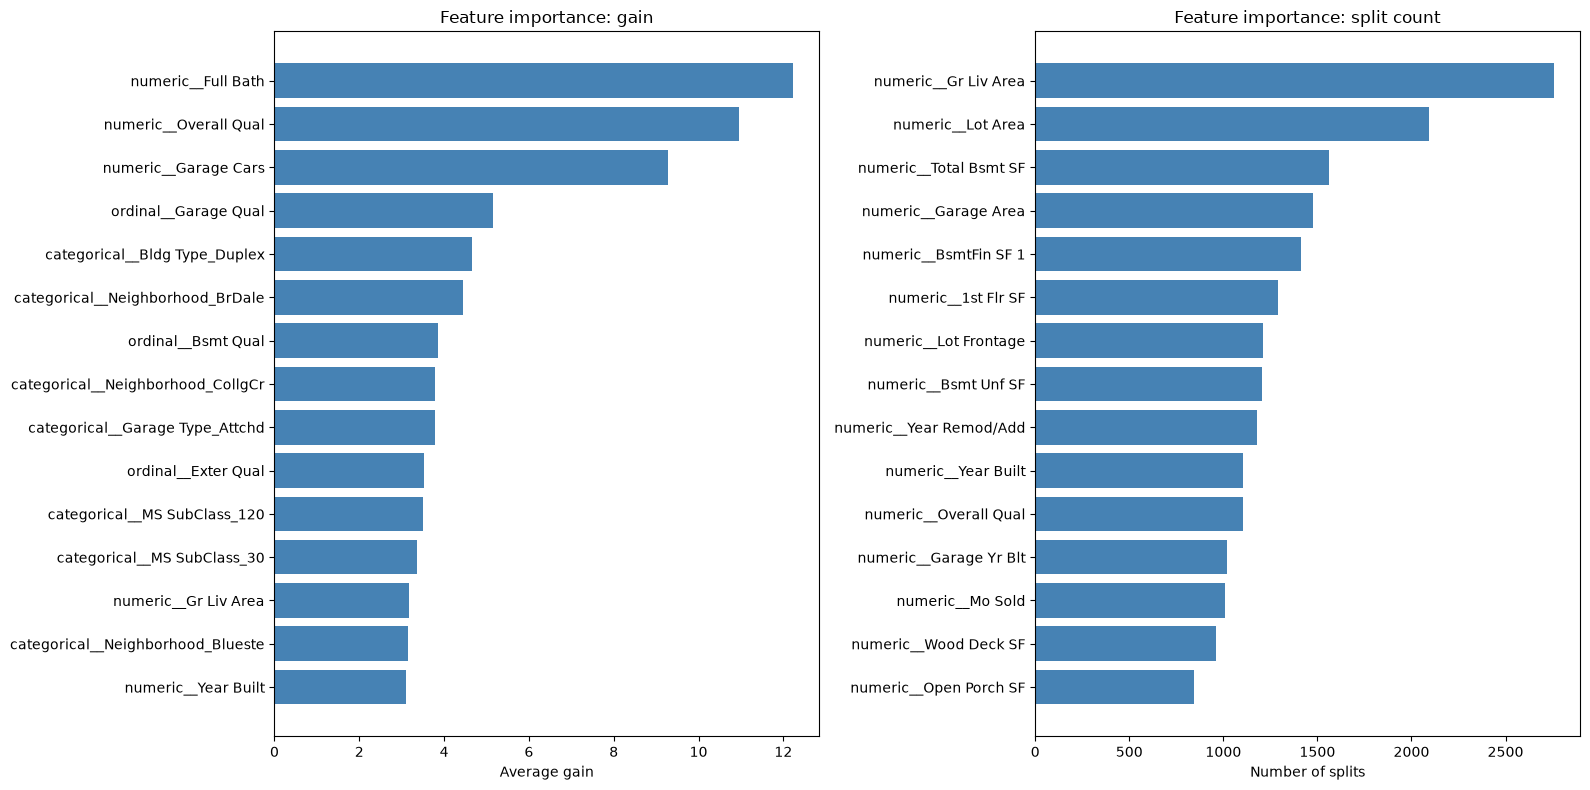

,gain,split
numeric__Full Bath,12.234,141.0
numeric__Overall Qual,10.943,1105.0
numeric__Garage Cars,9.268,158.0
ordinal__Garage Qual,5.163,93.0
categorical__Bldg Type_Duplex,4.651,1.0
categorical__Neighborhood_BrDale,4.439,15.0
ordinal__Bsmt Qual,3.865,268.0
categorical__Neighborhood_CollgCr,3.795,101.0
categorical__Garage Type_Attchd,3.792,90.0
ordinal__Exter Qual,3.515,137.0


In [16]:
# Gain is average split improvement; weight is the number of times a feature splits.
xgb_model = model.named_steps["classifier"]
booster = xgb_model.get_booster()
feature_names = list(model.named_steps["preprocessor"].get_feature_names_out())


def importance_by_name(importance_type):
    raw_scores = booster.get_score(importance_type=importance_type)
    values = np.zeros(len(feature_names), dtype=float)
    for key, value in raw_scores.items():
        if key.startswith("f") and key[1:].isdigit():
            feature_index = int(key[1:])
            if feature_index < len(values):
                values[feature_index] = value
        elif key in feature_names:
            values[feature_names.index(key)] = value
    return pd.Series(values, index=feature_names, name=importance_type)


importance = pd.concat(
    [importance_by_name("gain"), importance_by_name("weight")], axis=1
).rename(columns={"weight": "split"})
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, column, title in zip(
    axes,
    ("gain", "split"),
    ("Feature importance: gain", "Feature importance: split count"),
):
    top = importance[column].nlargest(15).sort_values()
    ax.barh(top.index, top.values, color="steelblue")
    ax.set_title(title)
    ax.set_xlabel("Average gain" if column == "gain" else "Number of splits")
fig.tight_layout()
plt.show()
display(importance.sort_values("gain", ascending=False).head(15).round(3))


### Decision tree visualizations
The model has no early stopping, so “best tree” here means the individual tree with the highest sum of split gains. Run the helper cell once.


In [17]:
# There is no early stopping in this fit; define "best tree" as the individual
# tree with the largest sum of split gains, not a best boosting iteration.
tree_dumps = [
    json.loads(tree)
    for tree in booster.get_dump(dump_format="json", with_stats=True)
]


def sum_tree_gain(node):
    return float(node.get("gain", 0.0)) + sum(
        sum_tree_gain(child) for child in node.get("children", [])
    )


tree_gains = np.array([sum_tree_gain(tree) for tree in tree_dumps])
best_tree_index = int(tree_gains.argmax())


def draw_tree(tree, title):
    positions = {}
    next_leaf = [0]

    def assign_positions(node, depth=0):
        children = node.get("children", [])
        if children:
            child_x = [assign_positions(child, depth + 1) for child in children]
            x_position = sum(child_x) / len(child_x)
        else:
            x_position = next_leaf[0]
            next_leaf[0] += 1
        positions[node["nodeid"]] = (x_position, -depth)
        return x_position

    assign_positions(tree)
    max_depth = max(-point[1] for point in positions.values())
    fig, ax = plt.subplots(
        figsize=(max(14, next_leaf[0] * 0.55), max(7, max_depth * 1.8))
    )

    def render(node):
        x_position, y_position = positions[node["nodeid"]]
        children = node.get("children", [])
        if "leaf" in node:
            label = f"leaf = {float(node['leaf']):.2f}"
            color = "#e8f1fa"
        else:
            split_name = node["split"]
            if split_name.startswith("f") and split_name[1:].isdigit():
                split_name = feature_names[int(split_name[1:])]
            split_name = textwrap.shorten(split_name, width=30, placeholder="...")
            label = f"{split_name}\\n<= {float(node['split_condition']):.3g}"
            color = "#fff1cc"
        ax.text(
            x_position,
            y_position,
            label,
            ha="center",
            va="center",
            fontsize=7,
            bbox={"boxstyle": "round,pad=0.3", "facecolor": color, "edgecolor": "#555"},
        )
        for child in children:
            child_x, child_y = positions[child["nodeid"]]
            ax.plot(
                [x_position, child_x],
                [y_position - 0.08, child_y + 0.12],
                color="#666",
                linewidth=0.8,
            )
            render(child)

    render(tree)
    ax.set_title(title)
    ax.axis("off")
    ax.set_xlim(-1, max(1, next_leaf[0]))
    ax.set_ylim(-max_depth - 0.7, 0.7)
    fig.tight_layout()
    plt.show()


def show_tree(tree_index):
    boosting_round = tree_index // len(class_ids)
    tree_class = tree_index % len(class_ids)
    print(
        f"Tree {tree_index}; round {boosting_round}; class {class_names[tree_class]}; "
        f"sum of split gains {tree_gains[tree_index]:.2f}"
    )
    draw_tree(
        tree_dumps[tree_index],
        f"XGBoost tree {tree_index} - {class_names[tree_class]}",
    )



#### First tree


Tree 0; round 0; class < 100.000; sum of split gains 506.70


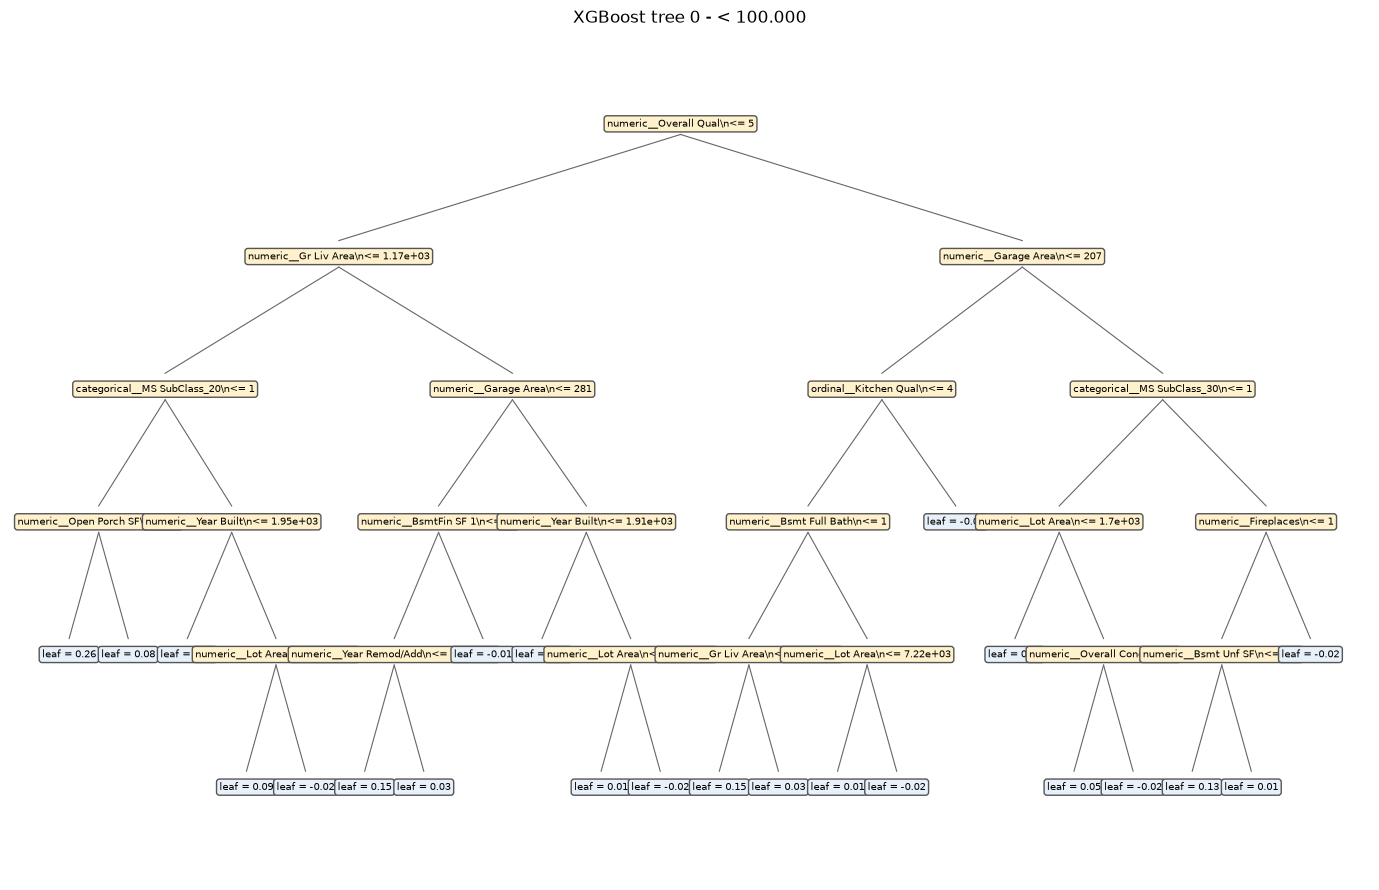

In [18]:
show_tree(0)

#### Highest-total-gain tree


Tree 4; round 0; class 250.000 - < 400.000; sum of split gains 604.95


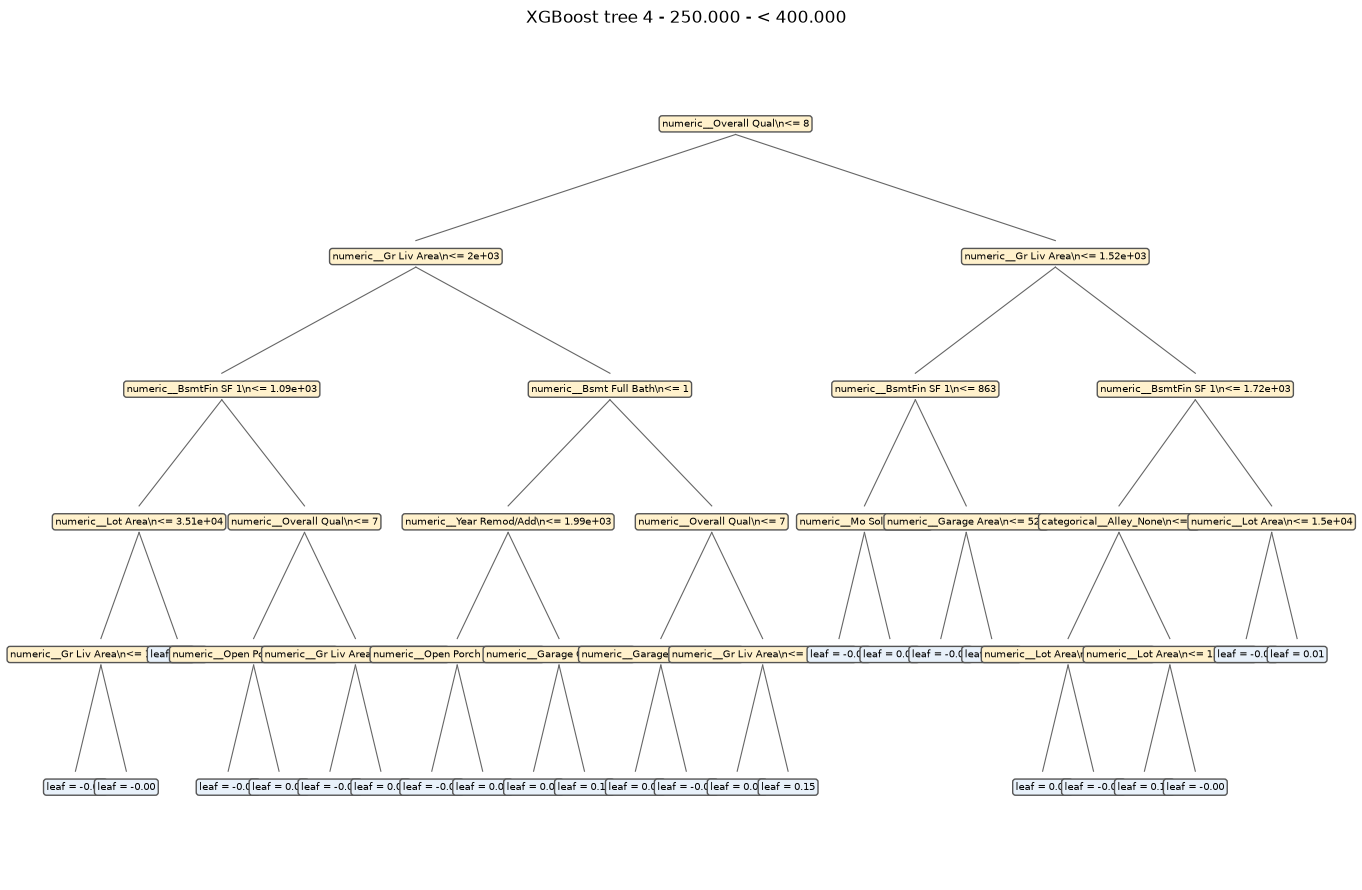

In [19]:
if best_tree_index == 0:
    print("The first tree is also the highest-total-gain tree.")
else:
    show_tree(best_tree_index)

### Interpretation
Summarizes the observed holdout results. Feature importance is predictive, not causal.


In [20]:
# Summarize observed test results; feature importance is not causal evidence.
weakest_class = min(
    class_names, key=lambda name: per_class_report[name]["recall"]
)
best_gain_feature = importance["gain"].idxmax()
print("Interpretation:")
print(
    f"- Test accuracy is {accuracy_score(y_test_array, y_pred):.1%}; "
    f"the majority-class baseline is {y_test.value_counts(normalize=True).max():.1%}."
)
print(
    f"- The weakest class by recall is {weakest_class} "
    f"({per_class_report[weakest_class]['recall']:.1%}); see the confusion matrix "
    "for where its errors go."
)
print(
    f"- The highest-gain feature is {best_gain_feature!r}. Gain indicates "
    "predictive split contribution, not a causal effect."
)
print(
    "- ROC and precision-recall curves are one-vs-rest. Cutoffs were selected "
    "from out-of-fold training predictions, then evaluated on the held-out test set."
)


Interpretation:
- Test accuracy is 77.1%; the majority-class baseline is 35.3%.
- The weakest class by recall is >= 400.000 (53.8%); see the confusion matrix for where its errors go.
- The highest-gain feature is 'numeric__Full Bath'. Gain indicates predictive split contribution, not a causal effect.
- ROC and precision-recall curves are one-vs-rest. Cutoffs were selected from out-of-fold training predictions, then evaluated on the held-out test set.
